# Migrating from LangChain to LangGraph

This notebook guides you through the conceptual and practical shifts when moving from LangChain Chains to LangGraph.

## Key Differences
| Feature | LangChain (Legacy) | LangGraph |
|---------|-------------------|-----------|
| Structure | DAG (Directed Acyclic Graph) - Chains | Cyclic Graphs (Loops possible) |
| State | `Memory` classes (opaque) | `State` Schema (Explicit, Typed) |
| Control Flow | Hardcoded classes (`SequentialChain`, `RouterChain`) | Nodes and Edges (Conditional) |


In [ ]:
from dotenv import load_dotenv
import os
load_dotenv()
OPENROUTER_API_KEY=os.getenv("OPENROUTER_API_KEY")
# Ensure you have your API keys set
# os.environ["OPENAI_API_KEY"] = "..."

## 1. Simple Linear Chain

**Scenario**: A prompt followed by an LLM call.

In [ ]:
# --- LangChain (LCEL) ---
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_openai import ChatOpenAI

llm=ChatOpenAI(
    model="liquid/lfm-2.5-1.2b-thinking:free",
    api_key=OPENROUTER_API_KEY,
    base_url="https://openrouter.ai/api/v1"
)
prompt = ChatPromptTemplate.from_template("Tell me a joke about {topic}")
chain = prompt | llm | StrOutputParser()
result = chain.invoke({"topic": "IT industry"})
print(result)

e:\PROST CODE\Agentic AI\RAG-full\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Joke:**  
Why did the IT professional bring a ladder to the server room?  
*To reach the ceiling of knowledge!*  

This skpayers a lighthearted take on IT challenges, poking fun at access rights while staying grounded in tech terms. Let me know if you'd like more! 😊


In [3]:
# --- LangGraph Equivalent ---
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

# 1. Define State
class State(TypedDict):
    topic: str
    joke: str

# 2. Define Nodes
def generate_joke(state: State):
    response = chain.invoke({"topic": state["topic"]}) # We can reuse the LCEL chain inside a node!
    return {"joke": response}

# 3. Build Graph
workflow = StateGraph(State)
workflow.add_node("generate_joke", generate_joke)
workflow.add_edge(START, "generate_joke")
workflow.add_edge("generate_joke", END)

app = workflow.compile()

# result = app.invoke({"topic": "AI"})
# print(result["joke"])

## Visualization
LangGraph provides built-in visualization, which is a huge valid over hidden chain logic.

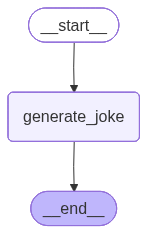

In [4]:
from IPython.display import Image, display
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    print("Graphviz not installed")

## 2. State & Memory

In LangChain, you used `ConversationBufferMemory`. In LangGraph, you define schema and simply append to the list in your state.

In [ ]:
from typing import Annotated
import operator

# Define State with 'reducer' equivalent to accumulating history
class ChatState(TypedDict):
    messages: Annotated[list, operator.add] # This tells LangGraph to APPEND new messages

def chatbot(state: ChatState):
    # Simple echo bot for demo
    last_message = state["messages"][-1]
    return {"messages": ["Echo: " + last_message]}

mem_graph = StateGraph(ChatState)
mem_graph.add_node("bot", chatbot)
mem_graph.add_edge(START, "bot")
mem_graph.add_edge("bot", END)

mem_app = mem_graph.compile()

# result = mem_app.invoke({"messages": ["Hello!"]})
# print(result)